In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df=pd.read_csv("/kaggle/input/datasets/camnugent/california-housing-prices/housing.csv")

In [3]:
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [4]:
df.dropna(inplace=True)

df.isna().sum()
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
from sklearn.model_selection import train_test_split
df1=df.drop("median_house_value",axis=1)
y=df["median_house_value"]
X_train, X_test, y_train, y_test= train_test_split(df1,y,test_size=0.2)

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

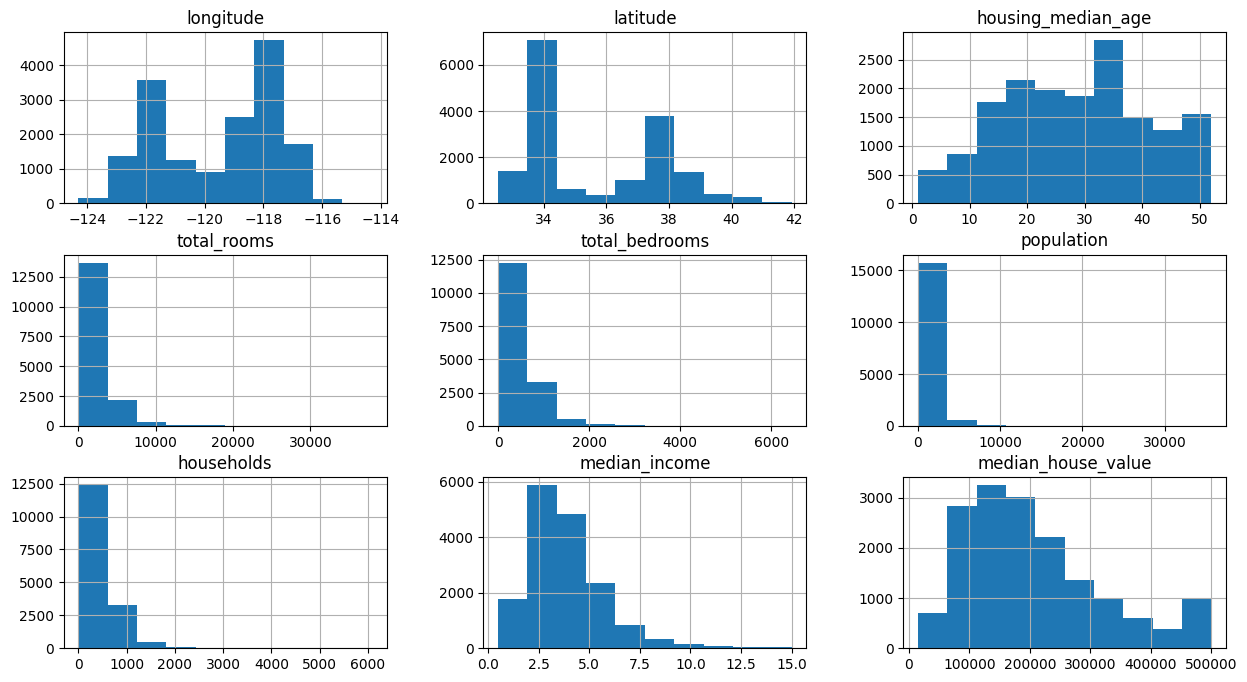

In [8]:
Train_data= X_train.join(y_train)
Train_data.hist(figsize=(15,8))

In [9]:
def corr_mat(x):
    numeric_df=x.select_dtypes(include=[np.number])
    mat_corr=numeric_df.corr()
    sns.heatmap(mat_corr,annot=True,fmt=".2f",cmap="coolwarm")
    plt.title("Correlation Matrix")
    plt.figure(figsize=(20,13))
    plt.show()

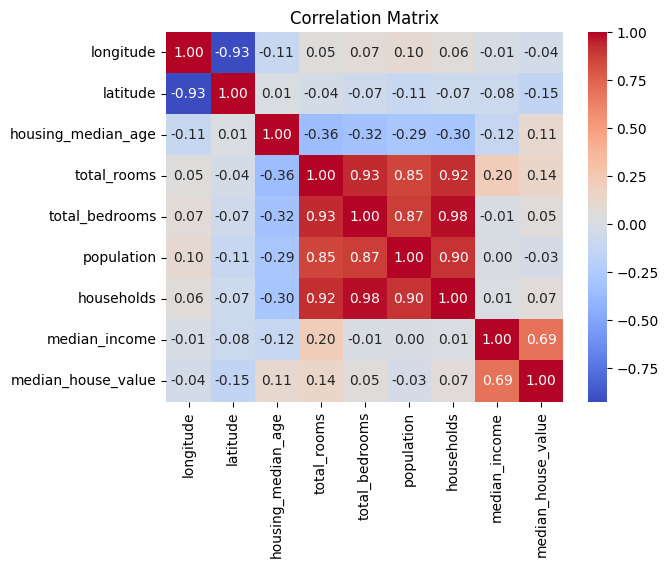

<Figure size 2000x1300 with 0 Axes>

In [10]:
corr_mat(Train_data)


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

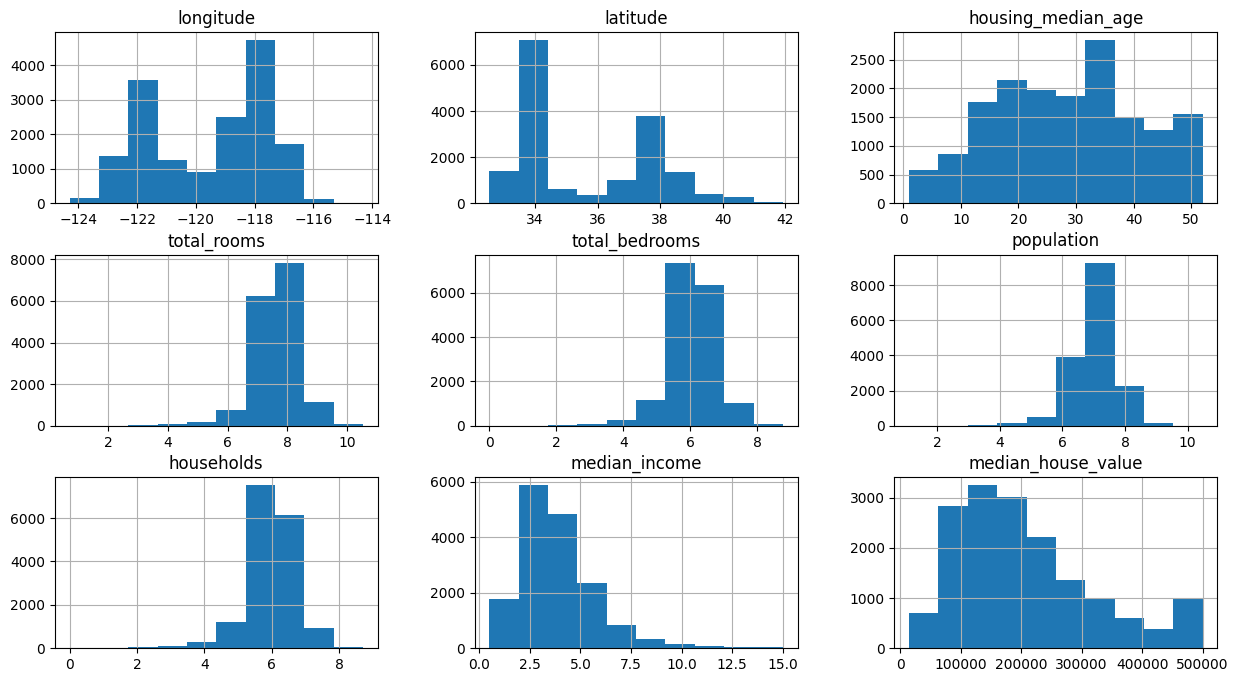

In [11]:
for i in ['households','total_rooms','total_bedrooms', 'population']:
    Train_data[i]=np.log(Train_data[i])
Train_data.hist(figsize=(15,8))



In [12]:
Train_data["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     7214
INLAND        5227
NEAR OCEAN    2086
NEAR BAY      1817
ISLAND           2
Name: count, dtype: int64

In [13]:
pd1=pd.get_dummies(Train_data.ocean_proximity,dtype=int)
Train_data=Train_data.join(pd1).drop(['ocean_proximity'],axis=1)
Train_data

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
9018,-118.72,34.14,7.0,10.080210,8.390949,9.197559,8.297045,5.4032,318500.0,0,0,0,0,1
1264,-121.70,37.98,9.0,8.032360,6.251904,7.353722,6.238325,5.1041,172900.0,0,1,0,0,0
16078,-122.49,37.73,48.0,7.081709,5.204007,6.208590,5.293305,6.2642,438500.0,0,0,0,0,1
9785,-121.32,35.95,31.0,5.918894,4.219508,6.171701,4.204693,3.5547,200000.0,0,0,0,0,1
3421,-118.42,34.28,34.0,7.600402,6.056784,7.779467,6.084499,2.8000,144300.0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15239,-117.25,33.01,16.0,8.266678,6.253829,7.282074,6.261492,7.7317,396000.0,0,0,0,0,1
15216,-117.11,32.95,11.0,8.454040,6.714171,7.706613,6.663133,4.9485,231800.0,1,0,0,0,0
9986,-122.58,38.59,33.0,7.122060,5.568345,6.289716,5.505332,3.5208,195800.0,0,1,0,0,0
16042,-122.47,37.72,46.0,7.281386,5.723585,6.705639,5.736572,3.0000,246700.0,0,0,0,0,1


In [14]:
Train_data.dtypes

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
<1H OCEAN               int64
INLAND                  int64
ISLAND                  int64
NEAR BAY                int64
NEAR OCEAN              int64
dtype: object

In [15]:
def corr_mat1(x):
    numeric_df=x.select_dtypes(include=[np.number,bool])
    mat_corr=numeric_df.corr()
    sns.heatmap(mat_corr,annot=True,fmt=".2f",cmap="coolwarm")
    plt.title("Correlation Matrix")
    plt.figure(figsize=(15,8))
    plt.show()
    

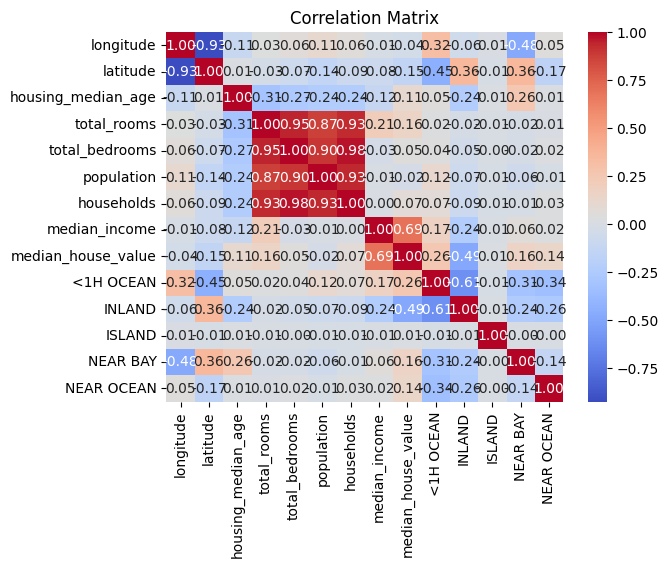

<Figure size 1500x800 with 0 Axes>

In [16]:
corr_mat1(Train_data)

In [17]:
from sklearn.linear_model import LinearRegression
x_train,Y_train=Train_data.drop(["median_house_value"], axis=1),Train_data["median_house_value"]
reg=LinearRegression()
reg.fit(x_train,Y_train)


LinearRegression()

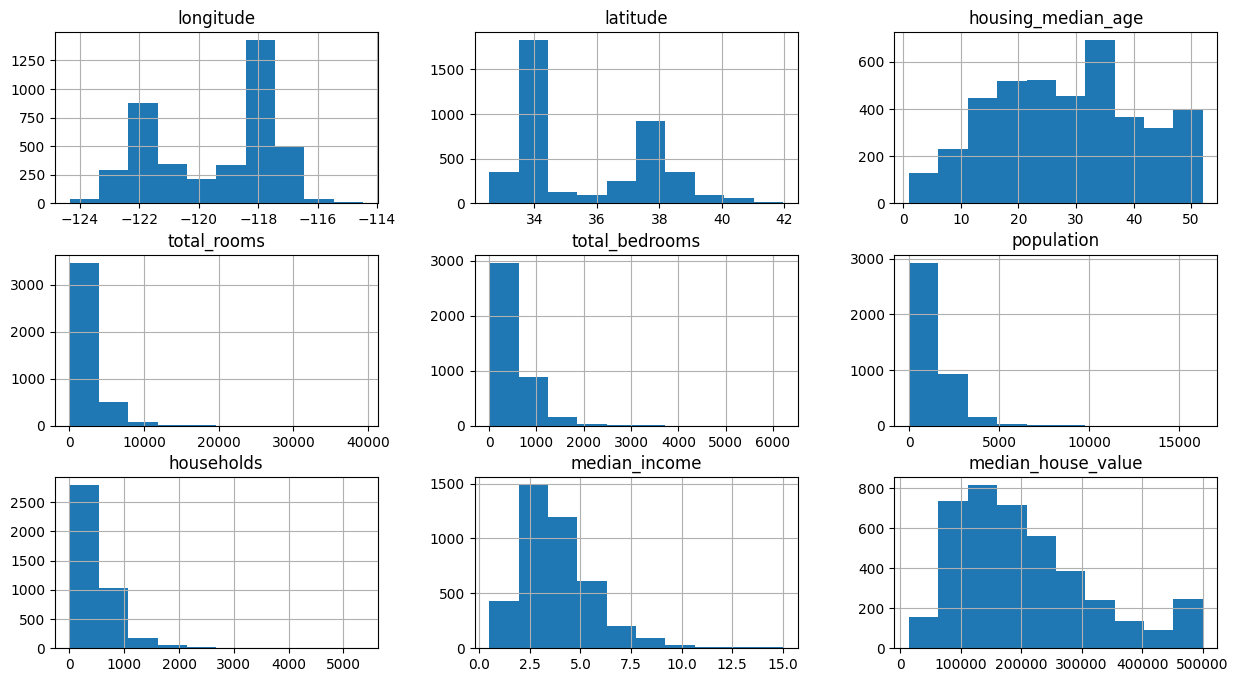

In [18]:
Test_data= X_test.join(y_test)
Test_data.hist(figsize=(15,8))
for i in ['households','total_rooms','total_bedrooms', 'population']:
    Test_data[i]=np.log(Test_data[i])
pd2=pd.get_dummies(Test_data.ocean_proximity,dtype=int)
Test_data=Test_data.join(pd2).drop(['ocean_proximity'],axis=1)

In [19]:
from sklearn.linear_model import LinearRegression
x_test,Y_test=Test_data.drop(["median_house_value"], axis=1),Test_data["median_house_value"]
reg=LinearRegression()
reg.fit(x_test,Y_test)

LinearRegression()

In [20]:
reg.score(x_test,Y_test)

0.6683617842584475

In [21]:
from sklearn.ensemble import RandomForestRegressor
forest=RandomForestRegressor()
forest.fit(x_train,Y_train)

RandomForestRegressor()

In [22]:
forest.score(x_test,Y_test)

0.8151294150292541

In [23]:
x_test

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
13452,-117.41,34.10,29.0,7.216709,5.525453,6.654153,5.533389,3.1287,0,1,0,0,0
2299,-119.76,36.82,17.0,8.843904,7.303843,8.024862,7.281386,2.3375,0,1,0,0,0
3093,-118.48,35.61,17.0,8.294550,6.835185,7.386471,6.594413,1.6236,0,1,0,0,0
1054,-121.82,39.76,23.0,8.701180,7.017506,7.904704,7.046647,3.0068,0,1,0,0,0
17911,-121.98,37.36,33.0,7.366445,5.605802,6.695799,5.587249,5.7059,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10341,-117.80,33.78,17.0,8.327968,6.690842,7.800573,6.659294,4.7804,1,0,0,0,0
19056,-121.74,38.15,22.0,7.554859,5.786897,6.908755,5.843544,4.8173,0,1,0,0,0
2337,-119.67,36.83,4.0,7.670895,5.811141,6.931472,5.730100,5.0864,0,1,0,0,0
17154,-122.21,37.43,23.0,8.655389,6.919684,7.519150,6.788972,5.7211,0,0,0,0,1
